<a href="https://colab.research.google.com/github/Nayyab-018/PyTorch-CNN-Image-Classifier/blob/main/PyTorch_CNN_Image_Classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Training PyTorch CNN on: cpu


100%|██████████| 26.4M/26.4M [00:02<00:00, 9.28MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 139kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 2.66MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 17.6MB/s]


Epoch [1/5] - Loss: 0.4761 | Unseen Test Accuracy: 87.30%
Epoch [2/5] - Loss: 0.3035 | Unseen Test Accuracy: 89.66%
Epoch [3/5] - Loss: 0.2523 | Unseen Test Accuracy: 90.39%
Epoch [4/5] - Loss: 0.2219 | Unseen Test Accuracy: 91.34%
Epoch [5/5] - Loss: 0.1969 | Unseen Test Accuracy: 91.71%


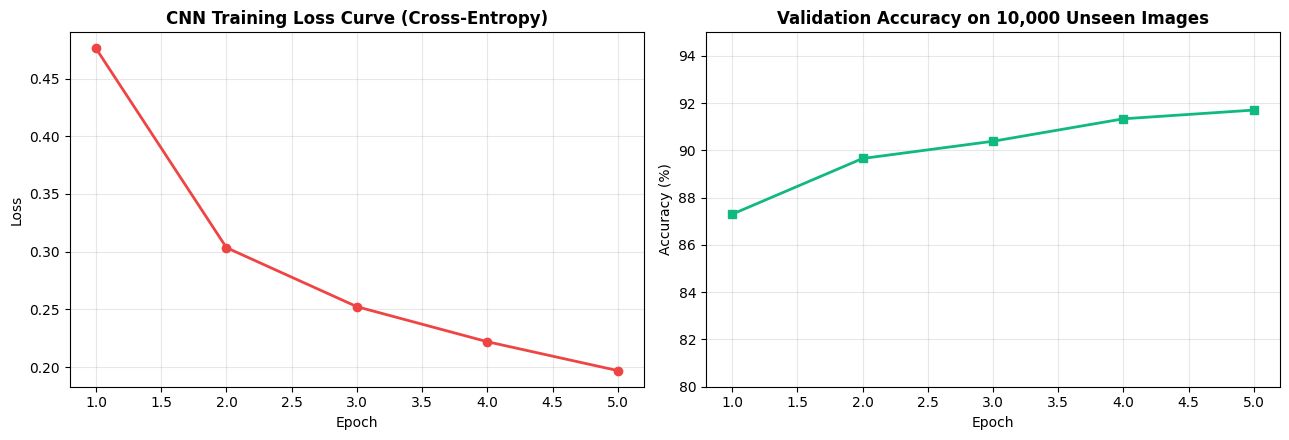

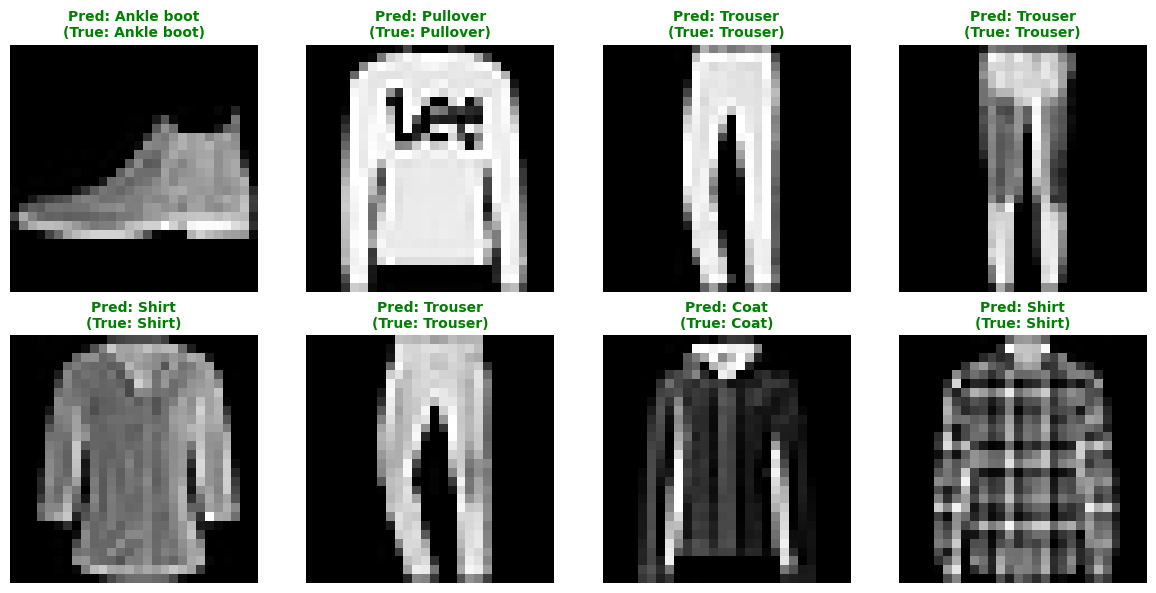

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

# --- 1. Device Setup ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Training PyTorch CNN on: {device}")

# --- 2. Load & Normalize Fashion-MNIST Dataset (70,000 Images) ---
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

train_dataset = datasets.FashionMNIST(root="./data", train=True, download=True, transform=transform)
test_dataset = datasets.FashionMNIST(root="./data", train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False)

class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

# --- 3. Build Custom Convolutional Neural Network (CNN) ---
class FashionCNN(nn.Module):
    def __init__(self):
        super(FashionCNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

model = FashionCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# --- 4. Train & Evaluate Over 5 Epochs ---
epochs = 5
train_losses, test_accuracies = [], []

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()

    avg_loss = running_loss / len(train_loader)
    train_losses.append(avg_loss)

    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    acc = 100 * correct / total
    test_accuracies.append(acc)
    print(f"Epoch [{epoch+1}/{epochs}] - Loss: {avg_loss:.4f} | Unseen Test Accuracy: {acc:.2f}%")

# --- 5. Save Training Curves & Visual Predictions ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
ax1.plot(range(1, epochs + 1), train_losses, marker="o", color="#ef4444", linewidth=2)
ax1.set_title("CNN Training Loss Curve (Cross-Entropy)", fontsize=12, fontweight="bold")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.grid(True, alpha=0.3)

ax2.plot(range(1, epochs + 1), test_accuracies, marker="s", color="#10b981", linewidth=2)
ax2.set_title("Validation Accuracy on 10,000 Unseen Images", fontsize=12, fontweight="bold")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Accuracy (%)")
ax2.set_ylim(80, 95)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("pytorch_training_curves.png", dpi=150)
plt.show()

sample_images, sample_labels = next(iter(test_loader))
sample_outputs = model(sample_images[:8].to(device))
_, sample_preds = torch.max(sample_outputs, 1)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for idx, ax in enumerate(axes.flat):
    img = sample_images[idx].squeeze().numpy() * 0.5 + 0.5
    true_name = class_names[sample_labels[idx]]
    pred_name = class_names[sample_preds[idx].item()]
    color = "green" if true_name == pred_name else "red"
    ax.imshow(img, cmap="gray")
    ax.set_title(f"Pred: {pred_name}\n(True: {true_name})", color=color, fontsize=10, fontweight="bold")
    ax.axis("off")

plt.tight_layout()
plt.savefig("pytorch_sample_predictions.png", dpi=150)
plt.show()
